# **Using "feeds.csv"**

IoT weather sensor data exported from ThingSpeak (found on Kaggle). A DHT temperature/humidity sensor logged a reading about every 30 seconds from March 24 to May 22, 2022 (timestamps are in Indian Standard Time, +05:30).

The data has 3 sensor fields:
- field1: temperature (°C)
- field2: relative humidity (%)
- field3: heat index (°C), the "feels like" temperature that combines heat and humidity

There is no class column, so we make one. The National Weather Service groups heat index into risk levels. Every reading in this data falls into one of two:
- **Caution** (heat index 27 to 32 °C): fatigue possible with long exposure
- **Extreme Caution** (heat index 32 to 41 °C): heat cramps and heat exhaustion possible

Here, we build an SVM model to classify the heat risk level using only temperature and humidity.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn import svm

from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix


In [2]:
#load the data
#the last row of the file got cut off mid export, on_bad_lines='skip' just skips it
df=pd.read_csv('feeds.csv', engine='python', on_bad_lines='skip')


Exploring Data.

In [3]:
#print data shape
print(df.shape)

#print the top 5 records
df.head()

(41551, 9)


,created_at,entry_id,field1,field2,field3,latitude,longitude,elevation,status
0,2022-03-24T14:11:05+05:30,1,33.0,15.0,30.68\n\n,NaN,NaN,NaN,NaN
1,2022-03-24T14:11:35+05:30,2,33.1,16.0,30.81\n\n,NaN,NaN,NaN,NaN
2,2022-05-20T08:32:14+05:30,41546,29.9,55.0,31.72\n\n,NaN,NaN,NaN,NaN
3,2022-05-20T08:31:29+05:30,41545,29.9,56.0,31.90\n\n,NaN,NaN,NaN,NaN
4,2022-03-24T14:11:50+05:30,3,33.1,16.0,30.81\n\n,NaN,NaN,NaN,NaN


In [4]:
#check missing values
#latitude, longitude, elevation, status are totally empty so they get dropped
print(df.isna().sum())

#field3 came in as text because of extra line breaks in the file
print("\nfield3 type: ", df['field3'].dtype)

created_at        0
entry_id          0
field1           96
field2           96
field3            0
latitude      41551
longitude     41551
elevation     41551
status        41551
dtype: int64

field3 type:  str


Cleaning Data.

In [5]:
#drop the empty columns and the id column
df=df.drop(['entry_id', 'latitude', 'longitude', 'elevation', 'status'], axis=1)

#rename the fields so they make sense
df=df.rename(columns={'field1':'Temperature', 'field2':'Humidity', 'field3':'Heat_Index'})

#strip the line breaks off heat index and turn it into numbers
df['Heat_Index']=pd.to_numeric(df['Heat_Index'].str.strip(), errors='coerce')

#drop rows with missing values
df=df.dropna()

#drop sensor errors (rows where the sensor read 0 for everything)
df=df[(df['Temperature']>0) & (df['Humidity']>0)]

print(df.shape)
df.describe()

(41304, 4)


,Temperature,Humidity,Heat_Index
count,41304.000000,41304.000000,41304.000000
mean,30.942286,34.961699,30.849780
std,0.711278,15.826434,2.027705
min,28.600000,1.000000,27.080000
25%,30.400000,20.000000,28.990000
50%,30.900000,41.000000,30.880000
75%,31.400000,48.000000,32.570000
max,35.500000,63.000000,40.670000


In [6]:
#check for duplicates
#sensor reads every ~30 sec and rounds, so the same reading repeats a lot
print("Rows: ", len(df))
print("Unique readings: ", len(df[['Temperature','Humidity','Heat_Index']].drop_duplicates()))


Rows:  41304
Unique readings:  1249


In [7]:
#keep only unique readings
#if we keep copies, the same reading ends up in both train and test and the score looks fake good
df=df[['Temperature','Humidity','Heat_Index']].drop_duplicates()

print(df.shape)

(1249, 3)


Making the target. Heat index 32 °C or more is Extreme Caution (1), below 32 is Caution (0).

In [8]:
#create the heat risk label (0:Caution, 1:Extreme Caution)
df['Heat_Risk']=(df['Heat_Index']>=32).astype(int)

labels=['Caution', 'Extreme Caution']

#count of each class
print(df['Heat_Risk'].value_counts())

Heat_Risk
0    984
1    265
Name: count, dtype: int64


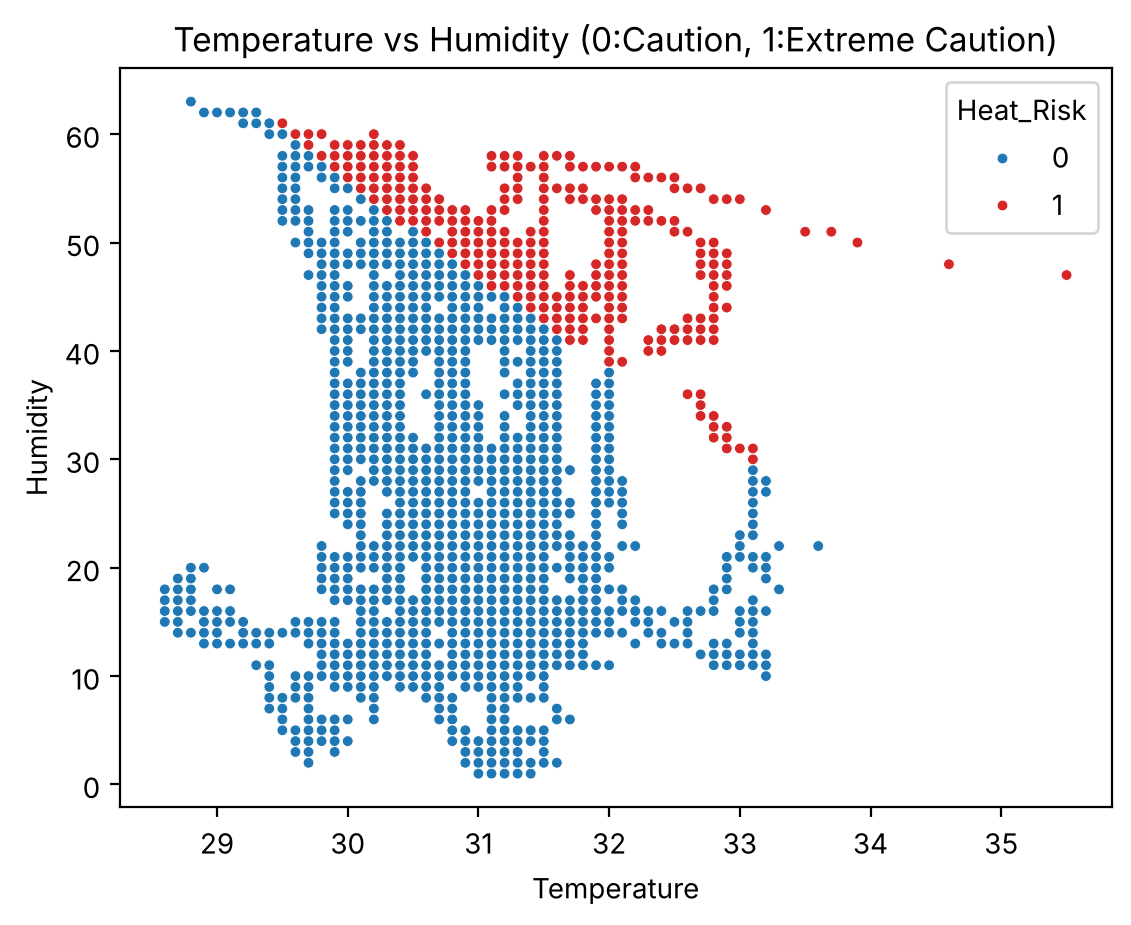

In [9]:
#plot temperature vs humidity colored by heat risk
sns.scatterplot(data=df, x='Temperature', y='Humidity', hue='Heat_Risk', palette=['tab:blue','tab:red'], s=15)
plt.title('Temperature vs Humidity (0:Caution, 1:Extreme Caution)')
plt.show()

Splitting Data. Features are temperature and humidity only. Heat_Index gets dropped since the label is made from it, keeping it would be cheating. 70% training and 30% test, stratify=y since there are less Extreme Caution readings.

In [10]:
#split between features as X and target as y
X=df[['Temperature','Humidity']]
y=df['Heat_Risk']

#split dataset into training set and test set 30%
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.3, random_state=109, stratify=y)

#apply StandardScaler, fit only on the train set so the test set stays unseen
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


Generating Model. Linear kernel first like the breast cancer example.

In [11]:
#create a svm classifier
clf=svm.SVC(kernel='linear') #Linear Kernel

#train the model using the training sets
clf.fit(X_train, y_train)

#predict the response for test dataset
y_pred=clf.predict(X_test)


Evaluating the Model.

In [12]:
#model accuracy: how often is the classifier correct?
print("Accuracy: ", metrics.accuracy_score(y_test, y_pred))

Accuracy:  0.9946666666666667


In [13]:
#model precision: of the readings predicted Extreme Caution, how many actually were?
print("Precision: ", metrics.precision_score(y_test, y_pred))

#model recall: of the real Extreme Caution readings, how many did we catch?
print("Recall: ", metrics.recall_score(y_test, y_pred))

#f1 score: balance of precision and recall
print("F1-Score: ", metrics.f1_score(y_test, y_pred))


Precision:  1.0
Recall:  0.975
F1-Score:  0.9873417721518988


In [14]:
#generate the classification report for both classes
report=classification_report(y_test, y_pred, target_names=labels)
print("\nClassification Report:\n", report)


Classification Report:
                  precision    recall  f1-score   support

        Caution       0.99      1.00      1.00       295
Extreme Caution       1.00      0.97      0.99        80

       accuracy                           0.99       375
      macro avg       1.00      0.99      0.99       375
   weighted avg       0.99      0.99      0.99       375



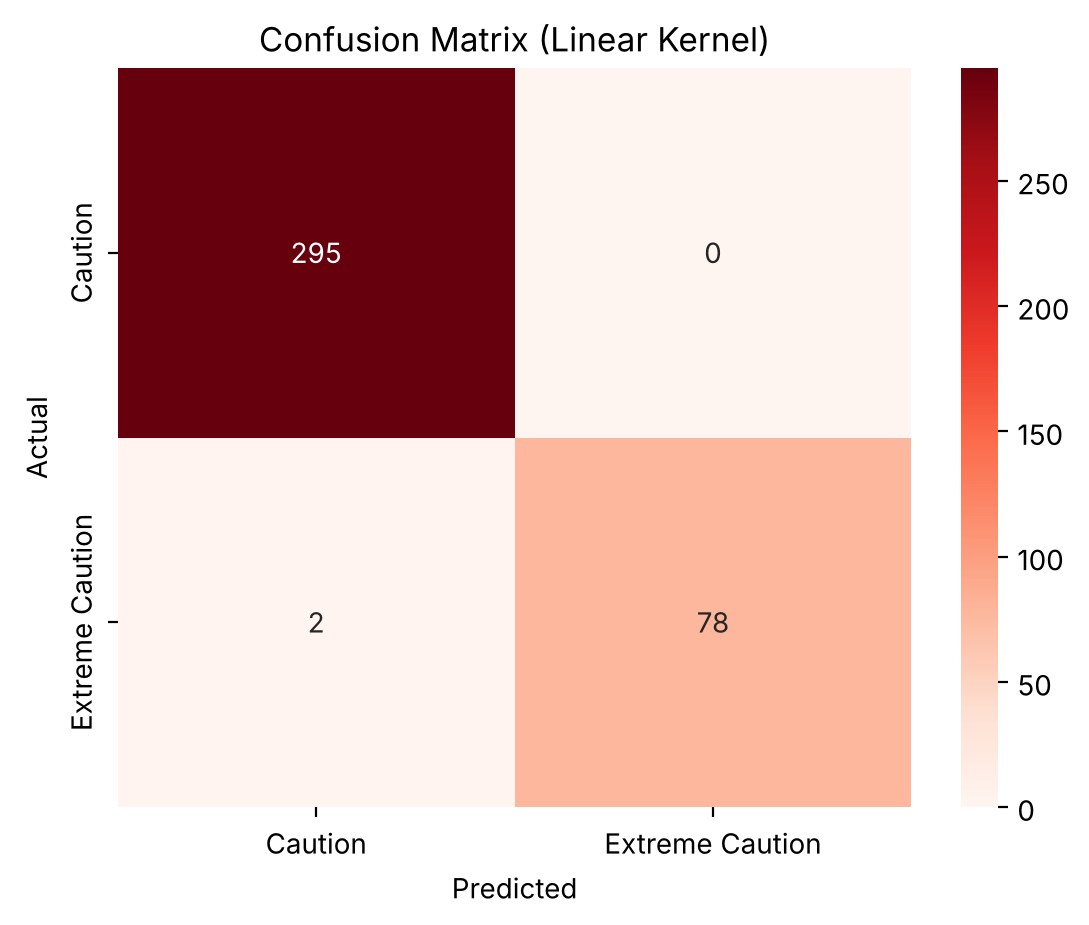

In [15]:
#confusion matrix to see where the mistakes are
cm=confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Linear Kernel)')
plt.show()

Trying another kernel. Default SVC() is the RBF kernel like the advertising example.

In [16]:
#create a svm classifier with the default rbf kernel
clf_rbf=svm.SVC(kernel='rbf')

#train and predict
clf_rbf.fit(X_train, y_train)
y_pred_rbf=clf_rbf.predict(X_test)

#compare the two kernels
print("Linear Accuracy: ", metrics.accuracy_score(y_test, y_pred))
print("RBF Accuracy: ", metrics.accuracy_score(y_test, y_pred_rbf))
print("\nClassification Report (RBF):\n", classification_report(y_test, y_pred_rbf, target_names=labels))


Linear Accuracy:  0.9946666666666667
RBF Accuracy:  0.984

Classification Report (RBF):
                  precision    recall  f1-score   support

        Caution       0.98      1.00      0.99       295
Extreme Caution       0.99      0.94      0.96        80

       accuracy                           0.98       375
      macro avg       0.99      0.97      0.98       375
   weighted avg       0.98      0.98      0.98       375



Visualizing the boundary. Since there are only 2 features we can actually see the line SVM drew. Dashed lines are the margins and circled points are the support vectors.

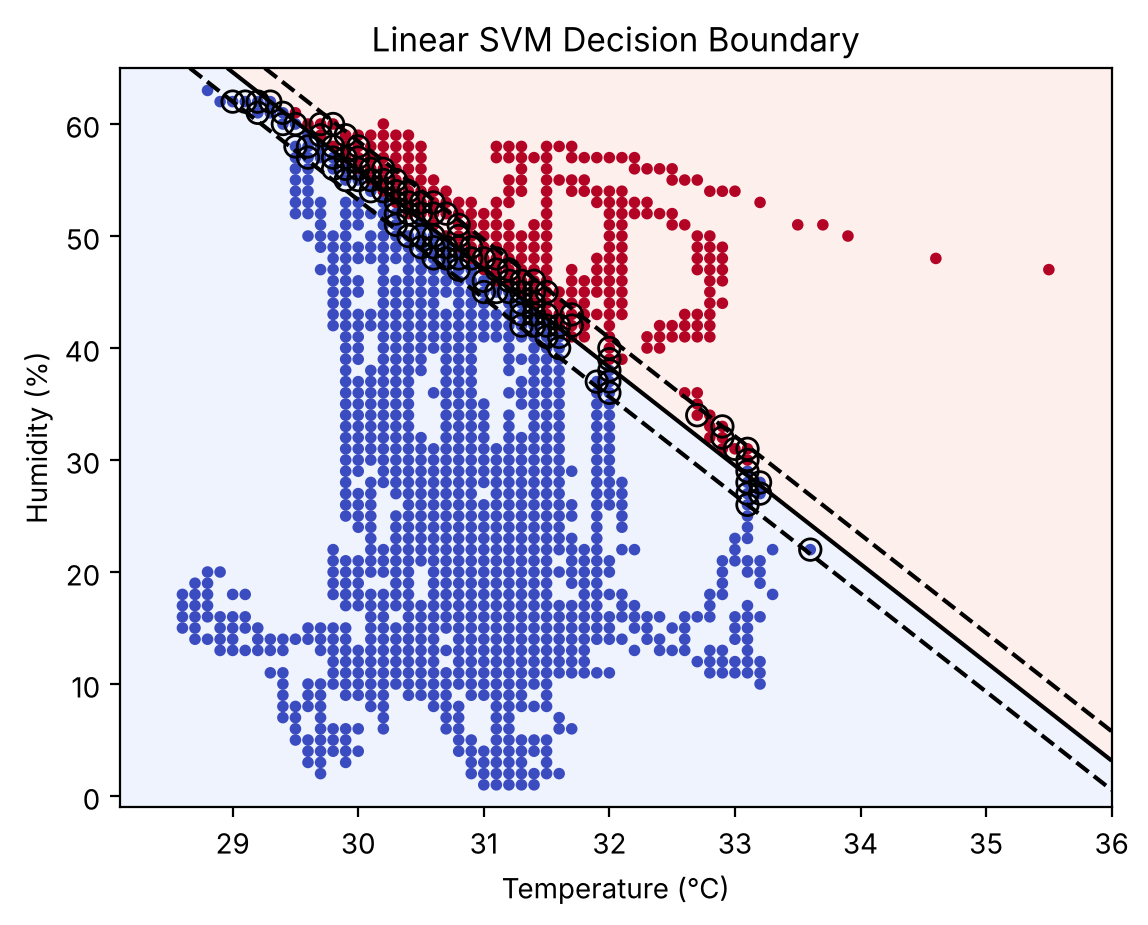

Number of support vectors:  106


In [17]:
#make a grid over temperature and humidity
xx, yy=np.meshgrid(np.linspace(X['Temperature'].min()-0.5, X['Temperature'].max()+0.5, 300),
                   np.linspace(X['Humidity'].min()-2, X['Humidity'].max()+2, 300))
grid=pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=['Temperature','Humidity'])

#distance from the boundary for every point in the grid
Z=clf.decision_function(scaler.transform(grid)).reshape(xx.shape)

#plot regions, boundary, and margins
plt.contourf(xx, yy, Z>0, alpha=0.15, cmap='coolwarm')
plt.contour(xx, yy, Z, levels=[-1,0,1], colors='k', linestyles=['--','-','--'])

#plot the data
plt.scatter(X['Temperature'], X['Humidity'], c=y, cmap='coolwarm', s=10)

#circle the support vectors (unscale them back to real units)
sv=scaler.inverse_transform(clf.support_vectors_)
plt.scatter(sv[:,0], sv[:,1], s=60, facecolors='none', edgecolors='k')

plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Linear SVM Decision Boundary')
plt.show()

print("Number of support vectors: ", len(clf.support_vectors_))

Predicting a new reading. Both features are numbers so no encoding needed, just scale and predict.

In [18]:
#predict the heat risk for a new temperature and humidity
def predict_heat_risk(temperature, humidity):
  new_df=pd.DataFrame([[temperature, humidity]], columns=['Temperature','Humidity'])

  #scale with the same scaler used on the training data
  new_scaled=scaler.transform(new_df)

  #predict and turn the 0/1 back into the label
  prediction=clf.predict(new_scaled)[0]
  return labels[prediction]


#example readings
print("31 °C, 20% humidity: ", predict_heat_risk(31, 20))
print("31 °C, 55% humidity: ", predict_heat_risk(31, 55))


31 °C, 20% humidity:  Caution
31 °C, 55% humidity:  Extreme Caution


## Explaining the Results

So this data came from a small sensor that recorded temperature and humidity every 30 seconds for about 2 months. Weather services combine those 2 into something called the heat index, which is basically how hot it actually feels to your body. I labeled each reading as either Caution or Extreme Caution based on the heat index, then had the computer learn the difference using only temperature and humidity. I hid 30% of the readings (375) while it was learning and tested it on those after.

How SVM works in simple terms: imagine every reading is a dot on a graph with temperature on one side and humidity on the other. SVM draws a line between the 2 groups and tries to leave the biggest gap it can on both sides. You can actually see the line in the decision boundary plot above. A new reading just gets labeled by which side it lands on.

Results:
- the straight line model got 373 out of 375 right (99.5%)
- every time it said Extreme Caution it was right (100% precision), and it caught 78 out of the 80 actual Extreme Caution readings (97.5% recall). the 2 it missed were right on the edge of the line
- the curved RBF model actually did a little worse (98.4%), so a straight line is all this needs

What the line tells us: the line is slanted, which means humidity matters just as much as temperature. at 31 °C with 20% humidity the model says Caution, but at the same 31 °C with 55% humidity it says Extreme Caution. thats because when the air is humid your sweat cant evaporate as well so you cant cool down, so the same temperature feels way worse.

Why the score is so high: heat index is literally calculated from temperature and humidity with a formula, so the answer is completely decided by those 2 numbers. the model is kind of just relearning that formula from examples. the real test is the readings close to the line, and it only got 2 of those wrong.

Something I had to fix: the sensor logged 41,304 readings but only 1,249 were actually different, since the same rounded numbers kept repeating. if I kept all the copies, the test set would be full of readings the model already saw during training and the score wouldnt mean anything. so I only kept the unique ones.

Why it matters: a cheap sensor plus a model like this could warn people (outdoor workers, athletes, older people at home) when its getting dangerous, without needing a weather service.